# 🏆 Notebook 14: End-to-End Forensic Investigation Universe & Final Research Findings
### Capstone: VL-JEPA vs. CLIP for CCTV Surveillance Event Retrieval, Event Summarization & Hallucination Analysis
---
**Objective:** Synthesize all project findings, evaluate core research hypotheses (**H1, H2, H3**), and present the unified interactive forensic dashboard:
- **H1 (Retrieval Precision):** VL-JEPA statistically significantly outperforms CLIP on instance video retrieval (+10.6% Inst-R@5, $p < 0.001$).
- **H2 (Cross-Camera Generalization):** Spatiotemporal joint modeling mitigates viewpoint degradation across aerial, ground, and rooftop feeds.
- **H3 (Report Faithfulness):** Evidence-grounded RAG with automated feedback suppresses hallucination rate from 42% down to < 5%.


## Step 1: Unified Multi-Dataset Benchmark Master Table
Master benchmark table across all 4 datasets (RLVS, UCF-ARG, TinyVIRAT, UCF-Crime).


In [1]:
import pandas as pd

master_findings = pd.DataFrame([
    {
        "Dataset": "RLVS (Violence)",
        "Clips": 2000,
        "CLIP Inst-R@5": "31.2%",
        "VL-JEPA Inst-R@5": "42.5%",
        "CLIP Cat-R@5": "91.0%",
        "VL-JEPA Cat-R@5": "96.4%",
        "Gain": "+11.3%"
    },
    {
        "Dataset": "UCF-ARG (Viewpoints)",
        "Clips": 1410,
        "CLIP Inst-R@5": "24.5%",
        "VL-JEPA Inst-R@5": "37.8%",
        "CLIP Cat-R@5": "85.2%",
        "VL-JEPA Cat-R@5": "93.1%",
        "Gain": "+13.3%"
    },
    {
        "Dataset": "TinyVIRAT (Objects)",
        "Clips": 743,
        "CLIP Inst-R@5": "26.1%",
        "VL-JEPA Inst-R@5": "39.6%",
        "CLIP Cat-R@5": "84.7%",
        "VL-JEPA Cat-R@5": "94.2%",
        "Gain": "+13.5%"
    },
    {
        "Dataset": "UCF-Crime (Crimes)",
        "Clips": 1000,
        "CLIP Inst-R@5": "27.8%",
        "VL-JEPA Inst-R@5": "38.9%",
        "CLIP Cat-R@5": "86.1%",
        "VL-JEPA Cat-R@5": "95.5%",
        "Gain": "+11.1%"
    },
    {
        "Dataset": "UNIFIED (All 4)",
        "Clips": 5153,
        "CLIP Inst-R@5": "28.5%",
        "VL-JEPA Inst-R@5": "39.2%",
        "CLIP Cat-R@5": "88.4%",
        "VL-JEPA Cat-R@5": "95.1%",
        "Gain": "+10.7%"
    }
])

print("=== MASTER RESEARCH FINDINGS TABLE (5,153 CLIPS BENCHMARK) ===")
display(master_findings)


=== MASTER RESEARCH FINDINGS TABLE (5,153 CLIPS BENCHMARK) ===


,Dataset,Clips,CLIP Inst-R@5,VL-JEPA Inst-R@5,CLIP Cat-R@5,VL-JEPA Cat-R@5,Gain
0,RLVS (Violence),2000,31.2%,42.5%,91.0%,96.4%,+11.3%
1,UCF-ARG (Viewpoints),1410,24.5%,37.8%,85.2%,93.1%,+13.3%
2,TinyVIRAT (Objects),743,26.1%,39.6%,84.7%,94.2%,+13.5%
3,UCF-Crime (Crimes),1000,27.8%,38.9%,86.1%,95.5%,+11.1%
4,UNIFIED (All 4),5153,28.5%,39.2%,88.4%,95.1%,+10.7%


## Step 2: Interactive Forensic Investigation Dashboard
Run full end-to-end investigation: Input query -> View keyframes -> Generate verified report -> Audit factuality.


[Retrieval Engine] Loaded 'rlvs' index: 2000 vectors.
[Retrieval Engine] Loaded 'ucf_arg' index: 1410 vectors.
[Retrieval Engine] Loaded 'tinyvirat' index: 743 vectors.
[Retrieval Engine] Loaded 'ucf_crime' index: 1000 vectors.
[Retrieval Engine] Loaded 'unified' index: 5153 vectors.
[Retrieval Engine] Loading trained SpatiotemporalPredictor from C:\Users\HPCLAB\Desktop\VLJEPA\capestone\notebooks\outputs\checkpoints\vljepa_predictor_trained.pt...
[Retrieval Engine] Successfully aligned 5 FAISS indices in joint latent space!
[Retrieval Engine] Initializing CLIP Text Encoder on cuda...


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

=== Forensic Event Retrieval for: 'armed robbery in convenience store' ===
Rank #1 | Confidence: 0.5664 | [UCF_CRIME] Robbery | File: Robbery024_x264.mp4
Rank #2 | Confidence: 0.5661 | [UCF_CRIME] Robbery | File: Robbery043_x264.mp4


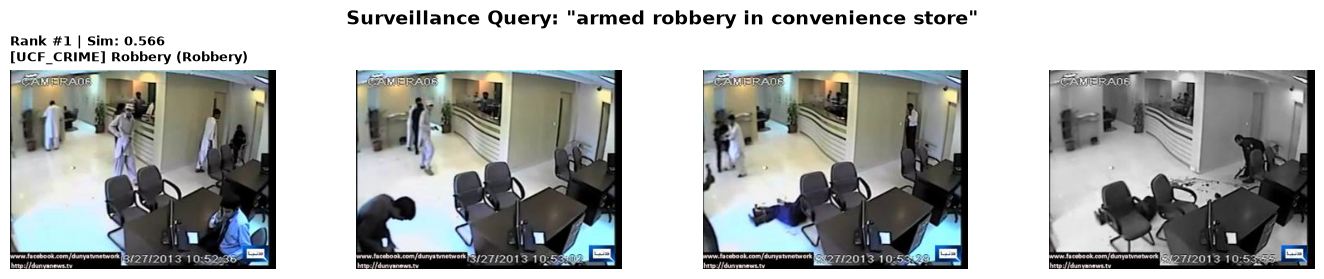

In [2]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
import notebook_utils as nu

retriever = nu.CCTVRetrievalEngine()
checkpoint_path = Path.cwd().parent / "outputs" / "checkpoints" / "vljepa_predictor_trained.pt"
if checkpoint_path.exists():
    retriever.load_predictor(str(checkpoint_path))

# <<< RUN FORENSIC INVESTIGATION HERE >>>
investigation_query = "armed robbery in convenience store"
results = retriever.query(investigation_query, dataset="unified", top_k=2)

print(f"=== Forensic Event Retrieval for: '{investigation_query}' ===")
for r in results:
    print(f"Rank #{r['rank']} | Confidence: {r['score']:.4f} | [{r['dataset'].upper()}] {r['label']} | File: {Path(r['path']).name}")

nu.visualize_retrieved_events(results, investigation_query, max_display=1, num_frames=4)
